In [1]:
%pylab inline
import os
import gc
import numpy as np
import astropy.io.fits as pyfits
from astropy.table import Table,vstack
import catutil as utilities
import pandas as pd
import catutil as utilities

import matplotlib as mpl
mpl.rcParams['savefig.dpi'] = 'figure'
mpl.rcParams['savefig.jpeg_quality'] = 100
matplotlib.rcParams['font.size'] = 18

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.ticker as mtick
import matplotlib.lines as mlines
from matplotlib.colors import LogNorm

Populating the interactive namespace from numpy and matplotlib


In [2]:
anaDir     =   './wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/'
simAname=   os.path.join(anaDir,'allSim.h5')
sims    =   pd.read_hdf(simAname,mode='r').to_records(index=True)
maskS    =   utilities.get_wl_flags(sims)
sims    =   sims[maskS]
weight_sims =   sims['weight']

/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/catutil.py:1708: RuntimeWarning: invalid value encountered in less
  (get_imag_A10(catalog)<25.5)& \


In [3]:
Dir='./wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/'
snr=[]
mag=[]
res=[]
absE=[]
for ii,fieldname in enumerate(utilities.field_names):
    # observation
    inFname =   os.path.join(Dir,'%s_no_m.fits' %(fieldname))
    data    =   pyfits.getdata(inFname)
    absE.append(utilities.get_abs_ellip(data))
    res.append(utilities.get_res(data))
    mag.append(utilities.get_imag(data))
    snr.append(utilities.get_snr(data))
    del data
    gc.collect()
snr=np.hstack(snr)
mag=np.hstack(mag)
res=np.hstack(res)
absE=np.hstack(absE)
gc.collect()

0

Text(0, 0.5, 'reGauss resolution')

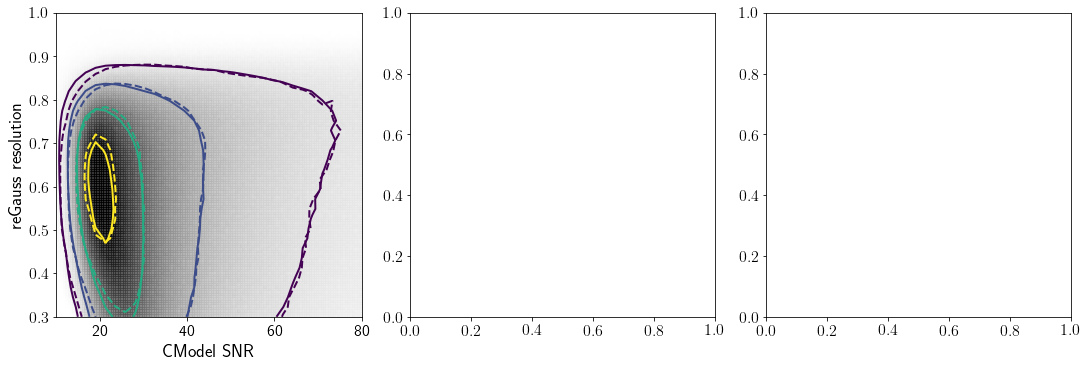

In [4]:
plt.close()
fig,axes = plt.subplots(1,3,figsize=(15, 5),constrained_layout=True)

"""
# The First Panel
"""
ax = axes[0]
counts1= np.histogram2d(snr, res, 32, range=[[10,80],[0.3,1]], normed=True)[0]
ax.contour(counts1.T,extent=[10,80,0.3,1],cmap='viridis', levels=[0.01, 0.025, 0.05, 0.075])
ax.hist2d(snr, res, 128, range=[[10,80],[0.3,1]], cmap='gray_r', normed=True,vmax=0.08,alpha=0.8);
print([0.01,0.025,0.05,0.075]/counts1.max())

counts2= np.histogram2d(sims['snr'], sims['res'], 32, weights=weight_sims, range=[[10,80],[0.3,1]], normed=True)[0]
ax.contour(counts2.T,extent=[10,80,0.3,1],cmap='viridis',linestyles='dashed', levels=[0.01, 0.025, 0.05, 0.075])
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
ax.set_xlabel('CModel SNR')
ax.set_ylabel('reGauss resolution')
#ax.set_xscale('log')

In [10]:
"""
# The Second Panel
"""
ax = axes[1]
counts1= np.histogram2d(snr, absE, 32, range=[[10,80],[0.,2]], normed=True)[0]
ax.contour(counts1.T,extent=[10,80,0.,2],cmap='viridis', levels=[0.0065, 0.012, 0.025, 0.035])
ax.hist2d(snr, absE,128, range=[[10,80],[0.,2]], cmap='gray_r', normed=True,alpha=0.8,norm=LogNorm(vmin=0.0002,vmax=0.2));
print([0.0065, 0.012, 0.025, 0.035]/counts1.max())

counts2= np.histogram2d(sims['snr'], sims['absE'], 32, weights=weight_sims, range=[[10,80],[0.,2]], normed=True)[0]
ax.contour(counts2.T,extent=[10,80,0.,2], cmap='viridis', linestyles='dashed', levels=[0.0065,0.012,0.025,0.035])
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
ax.set_xlabel('CModel SNR')
ax.set_ylabel(r'reGauss $|e|$')
#ax.set_xscale('log')

"""
#  Adding legend
"""
data_line = mlines.Line2D([], [], color='black', ls='-', label='Data')
sims_line = mlines.Line2D([], [], color='black', ls='--',label='Simulation')
ax.legend(handles=[data_line,sims_line])

[0.14071329 0.25977839 0.54120498 0.75768697]


In [11]:
"""
# The third panel
"""
ax = axes[2]
counts1,xbins1,ybins1,image = ax.hist2d(snr, mag, 32, range=[[10,80],[22,24.5]], cmap='gray_r', normed=True,vmax=0.1);
ax.contour(counts1.T,extent=[10,80,22,24.5],cmap='viridis', levels=[0.01, 0.025, 0.05, 0.075])
ax.hist2d(snr, mag, 128, range=[[10,80],[22,24.5]], cmap='gray_r', normed=True,vmax=0.1,alpha=0.8,norm=LogNorm(vmin=0.005,vmax=0.1));
print([0.01, 0.025, 0.05, 0.075]/counts1.max())

counts2,xbins2,ybins2,image = ax.hist2d(sims['snr'], sims['mag'], 32, weights=weight_sims, range=[[10,80],[22,24.5]], cmap='gray_r', normed=True,vmax=0.1);
ax.contour(counts2.T,extent=[10,80,22,24.5], cmap='viridis', linestyles='dashed', levels=[0.01,0.025,0.05,0.075])
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
ax.set_xlabel('CModel SNR')
ax.set_ylabel('CModel mag')
ax.set_ylim(24.5,22)
#ax.set_xscale('log')

[0.13513885 0.33784713 0.67569426 1.01354139]


(24.5, 22)

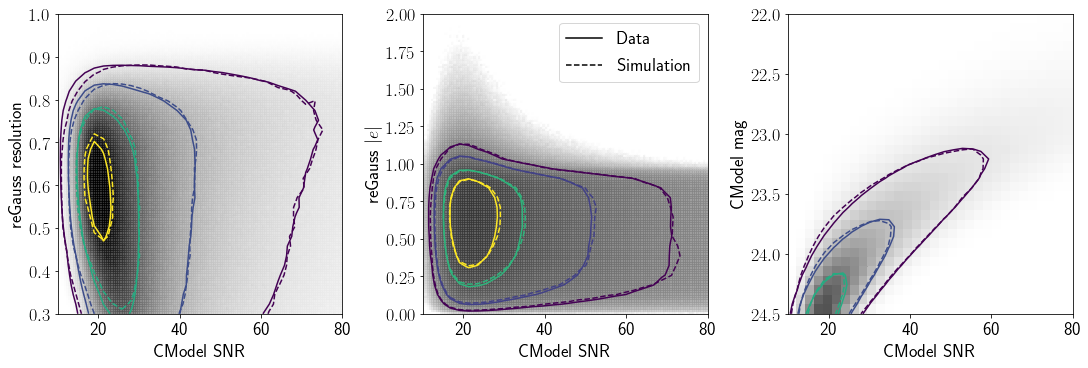

In [9]:
fig

In [10]:
"""
# Save figure
"""
pltDir  =   os.path.join(anaDir,'plot/galDis2D/')
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
fig.savefig(os.path.join(pltDir,'galDis2D-final_reCheck.eps' ))
fig.savefig(os.path.join(pltDir,'galDis2D-final_reCheck.png' ))